# TF-IDF
## Data preparation

In [1]:
import html
import re
import pandas as pd
import numpy as np
from IPython.core.pylabtools import figsize
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.tokenize import MWETokenizer
from Jieshu_utils_for_tokenization import *
from nltk import word_tokenize
from nltk.corpus import stopwords
from wordcloud import WordCloud

# read a dataset with 100 papers

hcai_paper = pd.read_csv("/Users/jieswang/PycharmProjects/Human_centered_AI_in_papers_and_patents/data/00-open_alex_datasets/hcai_paper_dataset_dropped_duplicates_2026-10-12_15-12-22.csv").sort_values(by='citations', ascending=False).head(100)

print("data prepared")

data prepared


## Text preprocessing

In [2]:
# download stopwords
stop_words = set(stopwords.words('english'))

def remove_stop_words(tokens):
    pattern = re.compile(r'^[a-zA-Z0-9_]+$')
    return [t for t in tokens if re.match(pattern, t) and t.lower() not in stop_words]

mwes_updated = [
    'world wide web', 'neural network', 'deep learning', 'internet of thing',
    'real time', 'artificial intelligence', 'machine learning',
    'object oriented', 'support vector machine',
    'expert system', 'natural language', 'principal component analysis',
    'lightweight directory access protocol', 'social network',
    'stem cell', 'random forest', 'x ray', 'mobile phone', 'n gram',
    'non linear', 'ad hoc network', 'fuzzy logic', 'operating system'
    'genetic algorithm','supervised learning','unsupervised learning', 'semi supervised learning','facial recognition','face recognition',
    'generative adversarial network','type 1','supply chain','three dimensional','gradient descent', 'reinforcement learning',
    'pattern recognition','speech recognition', 'search engine','virtual reality','augment reality','user interface']

multi_words_list_updated = [tuple(i.lower().split()) for i in mwes_updated]

multi_words_tokenizer = MWETokenizer(multi_words_list_updated).tokenize

tokenize_pipeline = [str.lower, clean, normalize, word_tokenize, multi_words_tokenizer, lemmatize, remove_stop_words]

def apply_pipeline(text, pipeline):
    for func in pipeline:
        text = func(text)
    return text

hcai_paper['abstract_tokenized'] = hcai_paper['abstract'].apply(lambda x: apply_pipeline(x, tokenize_pipeline))

print("abstract tokenized")

abstract tokenized


## Compute word frequencies


In [6]:
freq_df = hcai_paper['abstract_tokenized'].explode().value_counts().reset_index().rename(columns={'abstract_tokenized':'word', 'count':'frequency'})

# Display top 20 words
freq_df.head(20)

,word,frequency
0,human,388
1,ai,380
2,technology,142
3,research,137
4,use,127
5,system,120
6,future,110
7,model,95
8,data,93
9,design,91


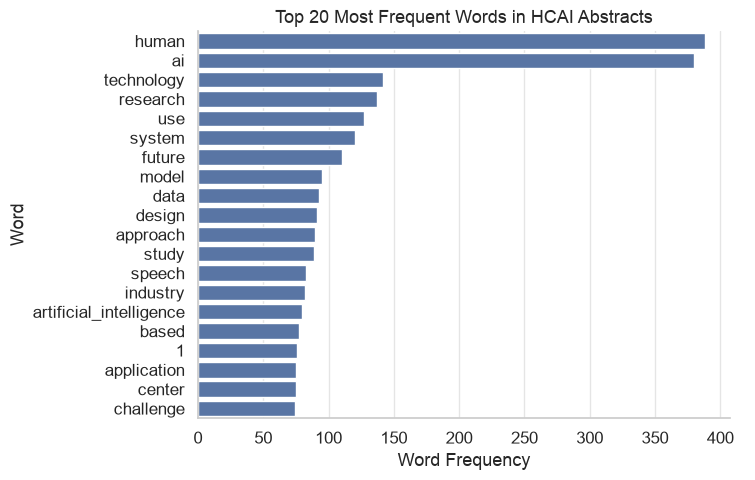

In [11]:
sns.set_theme(style="whitegrid", font_scale=1.1)

g=sns.catplot(kind='bar', data=freq_df.head(20),
              y='word', x='frequency', height=5, aspect=1.5)

plt.xlabel('Word Frequency')
plt.ylabel('Word')
plt.title('Top 20 Most Frequent Words in HCAI Abstracts')

plt.tight_layout()
# plt.show()

## Compute TF-IDF
TF-IDF (Term Frequency–Inverse Document Frequency) measures how important a word is to a document relative to the entire collection of documents.
- TF (Term Frequency): How frequently a word appears in a document.
- IDF (Inverse Document Frequency): How rare a word is across all documents.
- TF-IDF: Gives higher weights to words that are frequent in a particular document but less common across the corpus.

In [12]:
df = hcai_paper.dropna(subset=['abstract_tokenized']).copy()

# Convert token lists into strings
df['text'] = df['abstract_tokenized'].apply(lambda tokens: ' '.join(tokens))

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r'(?u)\b\w+\b'
)

# Compute TF-IDF
tfidf_matrix = tfidf_vectorizer.fit_transform(df['text'])

# Get feature names (words)
feature_names = tfidf_vectorizer.get_feature_names_out()

# Check matrix dimensions
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (100, 4060)


In [13]:
# Examine TF-IDF scores for individual papers
# We can convert the TF-IDF matrix into a DataFrame for easier inspection.

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=feature_names,
    index=df.index
)

# Display TF-IDF scores
tfidf_df.head()

,0,000,00003,00019978,00573978,01444978,030,031,05cha6,0821,...,yvonne,zaporowski,zebrowska,zero,zhang,zhaojiang,zhou,zisserman,zixiao,zuboff
7108,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7170,0.298667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7047,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5942,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6509,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
# Find the top 10 keywords for the first paper:

# Select the first paper
paper_tfidf = tfidf_df.iloc[0]

# Get top 10 keywords
top_keywords = paper_tfidf.sort_values(
    ascending=False
).head(10)

print(top_keywords)

causability       0.502295
explainability    0.262658
explainable       0.249020
dl                0.184367
medicine          0.184367
measurement       0.184367
property          0.172623
article           0.166839
encompass         0.156072
ai                0.147029
Name: 7108, dtype: float64


Interpretation: Words with higher TF-IDF scores are more distinctive to this particular paper relative to the other papers in the dataset.

## Identify top keywords across all papers
We can calculate the average TF-IDF score of each word across all documents.

In [15]:
# Calculate average TF-IDF scores
mean_tfidf = tfidf_matrix.mean(axis=0).A1

# Create DataFrame
tfidf_scores = pd.DataFrame({
    'word': feature_names,
    'mean_tfidf': mean_tfidf
})

# Sort by TF-IDF
tfidf_scores = tfidf_scores.sort_values(
    'mean_tfidf',
    ascending=False
)

# Display top 20 keywords
tfidf_scores.head(20)

,word,mean_tfidf
386,ai,0.094175
1902,human,0.068056
3676,technology,0.037027
2022,industry,0.034367
3168,research,0.033876
3630,system,0.033688
1173,design,0.031857
0,0,0.029146
3867,use,0.028852
1101,data,0.028570


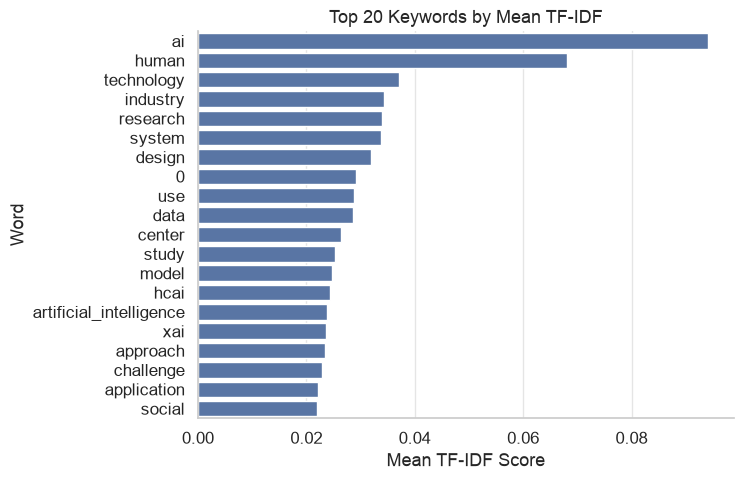

In [17]:
sns.set_theme(style="whitegrid", font_scale=1.1)

g=sns.catplot(kind='bar', data=tfidf_scores.head(20),
              y='word', x='mean_tfidf', height=5, aspect=1.5)

plt.xlabel('Mean TF-IDF Score')
plt.ylabel('Word')
plt.title('Top 20 Keywords by Mean TF-IDF')

plt.tight_layout()

Mean TF-IDF is useful for identifying words that receive relatively high weights across the collection. However, it is not a direct measure of how unique a word is to the corpus compared with other corpora. Common domain terms can still rank highly.

# Word Cloud
## Word cloud based on frequencies

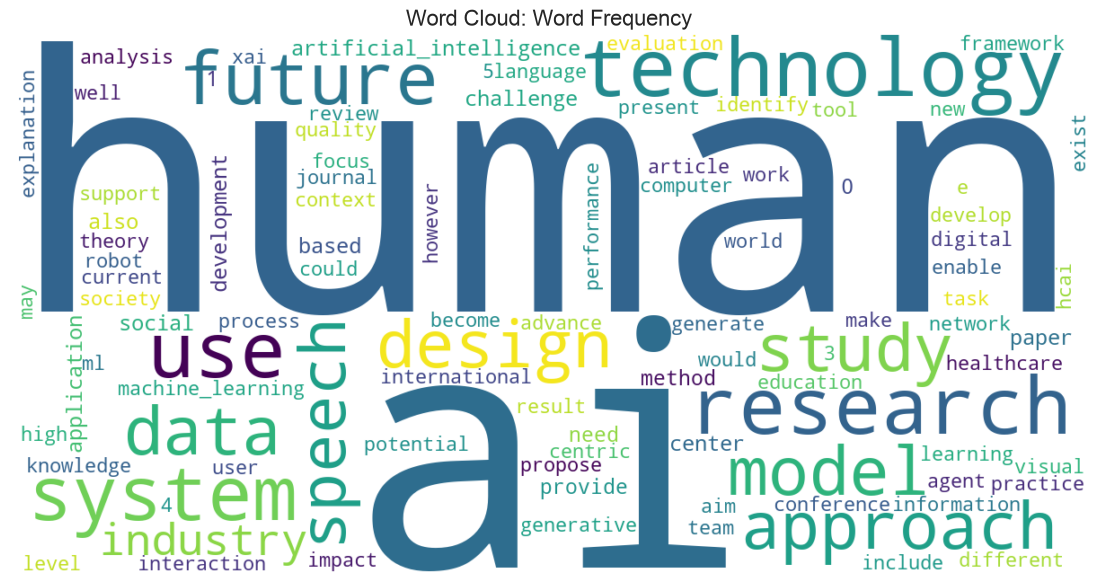

In [18]:
# Generate word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    colormap='viridis'
).generate_from_frequencies(word_freq)

# Display
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Word Frequency', fontsize=16)
plt.show()

## Create a word cloud using TF-IDF
- Instead of word frequencies, we can use mean TF-IDF scores to determine word sizes.
- Here, larger words have higher average TF-IDF scores across the research papers.

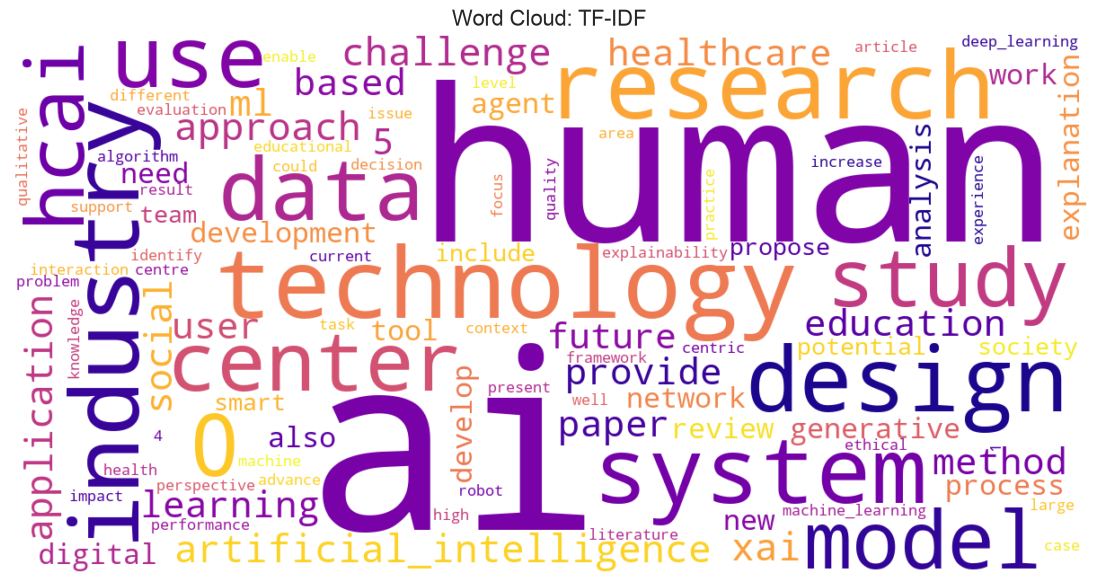

In [19]:
# Convert TF-IDF scores into a dictionary
tfidf_dict = dict(
    zip(
        tfidf_scores['word'],
        tfidf_scores['mean_tfidf']
    )
)

# Generate TF-IDF word cloud
wordcloud_tfidf = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    colormap='plasma'
).generate_from_frequencies(tfidf_dict)

# Display
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud_tfidf, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: TF-IDF', fontsize=16)
plt.show()

## Compare frequency and TF-IDF word clouds


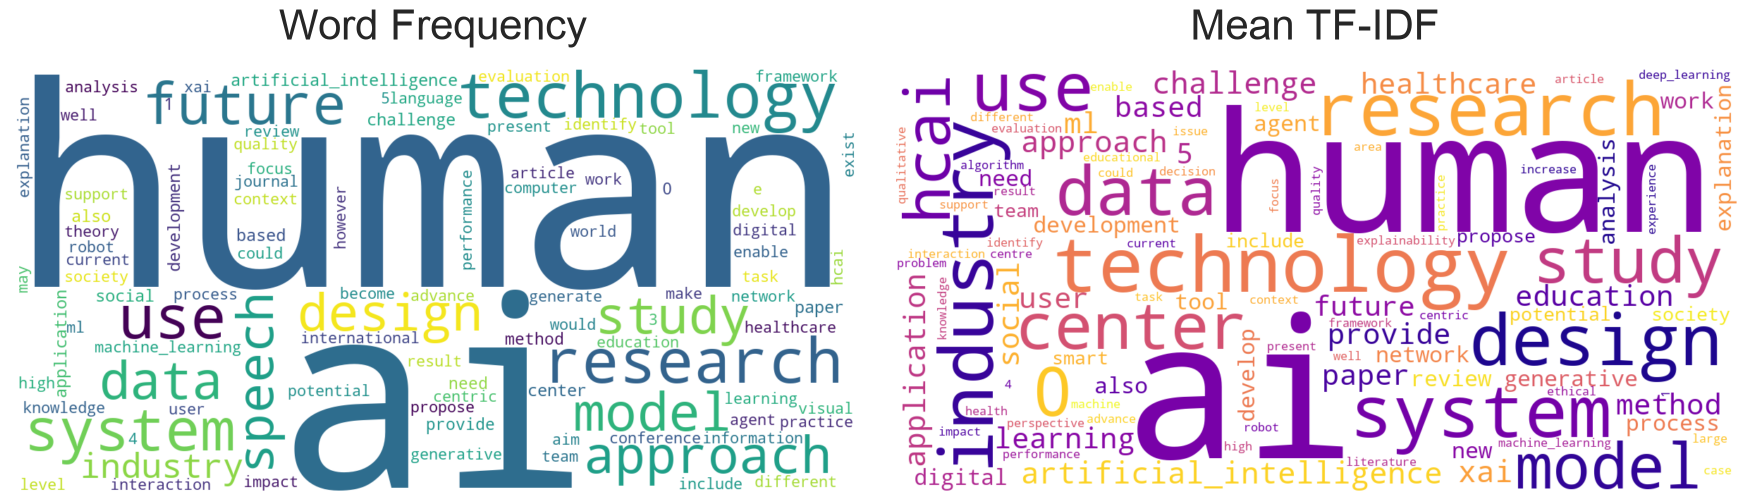

In [26]:
title_font_size=30
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Frequency word cloud
axes[0].imshow(wordcloud, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Word Frequency', fontsize=title_font_size, y=1.05)

# TF-IDF word cloud
axes[1].imshow(wordcloud_tfidf, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Mean TF-IDF', fontsize=title_font_size, y=1.05)

plt.tight_layout()
plt.show()